# Taller 2 — DQN (Javi)

El agente observa **tendencia y posición**, elige vender, mantener o comprar y aprende de la recompensa del entorno. DQN sustituye la tabla Q por una red que estima el valor de cada acción.

Compartimos con `taller_trader2_higinio.ipynb` el entorno, los generadores, las semillas, los bancos de validación/test y las métricas. Las definiciones comunes se incluyen aquí para ejecutar este notebook de forma autónoma, sin lanzar los entrenamientos A3C.

**Dos modos:** `smoke` comprueba el circuito con pocos episodios y solo validación; sus resultados no sirven para comparar algoritmos. `full` selecciona hiperparámetros en validación, usando cinco semillas y 1.000 episodios por entrenamiento, y después evalúa test. El modo predeterminado es `full`; cambia `MODE` en la siguiente celda para el experimento completo. No se utilizan los resultados de test de A3C para elegir DQN.


In [1]:
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from time import perf_counter
from copy import deepcopy
import hashlib
import json
import platform
import os
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
from torch import nn
from IPython.display import Markdown, display

MODE = os.environ.get("DQN_MODE", "full")  # "full" para la comparación definitiva
assert MODE in {"smoke", "full"}
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
OUTPUT_DIR = Path("artifacts") / f"dqn_{MODE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Modo: {MODE}; dispositivo: CPU; resultados: {OUTPUT_DIR}")


Modo: full; dispositivo: CPU; resultados: artifacts/dqn_full


## 1. El mismo entorno

Partimos de 1.000 unidades de capital. La comisión es del 0,1 % por operación y se invierte todo el efectivo. La observación usa seis precios; por eso 500 precios producen 494 decisiones. La acción se ejecuta al precio observado y después avanza el mercado.

La recompensa suma variaciones relativas y comisiones; **su suma no equivale al retorno compuesto de la cartera**. No cambiamos esta definición respecto a A3C. Al terminar se valora la posición abierta, sin forzar una venta adicional.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info


## 2. Los cuatro mercados

Conservamos las funciones de Higinio con un generador aleatorio explícito. Así, explorar o muestrear el replay no cambia los precios. Cada mercado se aprende con un modelo independiente. El mercado de tendencia puede crecer de forma extrema: sus resultados son sintéticos.


In [3]:
def _resolver_rng(rng):
    """Devuelve un RNG local; nunca depende del estado global de NumPy."""
    if rng is None:
        return np.random.default_rng()
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng debe ser una instancia de np.random.Generator")
    return rng


def generar_precios(n_steps=1000, rng=None):
    rng = _resolver_rng(rng)
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = rng.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

def generar_precios_browniano(
    n_steps=1000,
    start_price=100.0,
    mu=0.0001,
    sigma=0.02,
    rng=None,
):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    rng = _resolver_rng(rng)
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = rng.normal(
        (mu - 0.5 * sigma**2) * dt,
        sigma * np.sqrt(dt),
        n_steps,
    )
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

def generar_precios_reversion_media(
    n_steps=1000,
    start_price=100.0,
    mean_price=100.0,
    kappa=0.05,
    volatility=0.02,
    rng=None,
):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = (
            kappa * (mean_price - precios[t-1])
            + rng.normal(0, volatility * mean_price)
        )
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

def generar_precios_regimenes(
    n_steps=1000, start_price=100.0, rng=None
):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if rng.random() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = rng.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = rng.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios


### Ejemplos de los cuatro mercados

Tendencia y ciclo combina deriva creciente, oscilación y ruido; browniano modela retornos aleatorios; reversión a la media atrae el precio hacia 100; regímenes alterna fases alcistas y bajistas. Son ejemplos ilustrativos con las mismas semillas 100–103 de Higinio, separados de los bancos de evaluación.


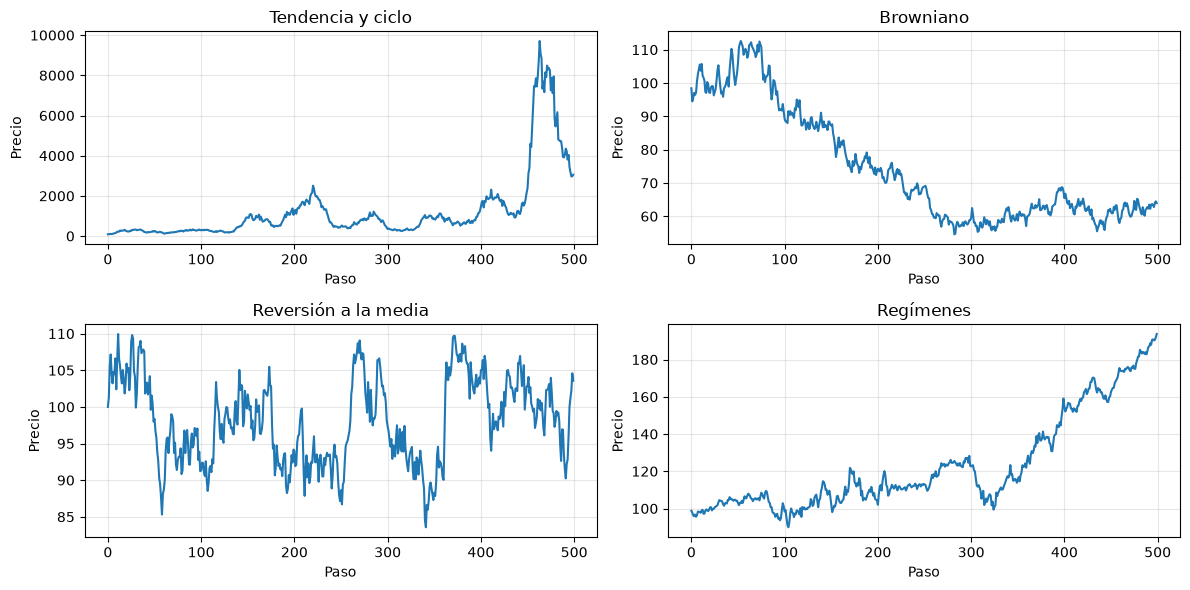

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (name, generator), seed in zip(axes.flat, [
    ("Tendencia y ciclo", generar_precios), ("Browniano", generar_precios_browniano),
    ("Reversión a la media", generar_precios_reversion_media), ("Regímenes", generar_precios_regimenes)], range(100,104)):
    ax.plot(generator(n_steps=500, rng=np.random.default_rng(seed)))
    ax.set(title=name, xlabel="Paso", ylabel="Precio")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Protocolo común y huellas

Entrenamiento: semillas **101, 202, 303, 404 y 505**. Validación: 50 series por mercado, semilla de precios 5.000. Test: 200 series, semilla 10.000. Todas tienen 500 precios. Las semillas de acciones son 6.000 y 20.000 respectivamente.

Los identificadores de mercado y el orden de los argumentos de `SeedSequence` forman parte del protocolo. Verificamos las huellas antes de entrenar. Generar test para verificar su identidad no implica usarlo para ajustar modelos.


In [5]:
@dataclass(frozen=True)
class EvaluationProtocol:
    """Define un banco de evaluación reproducible e independiente."""

    name: str
    n_series: int
    n_steps: int
    price_seed: int
    action_seed: int

    def __post_init__(self):
        if not self.name:
            raise ValueError("name no puede estar vacío")
        if self.n_series <= 0:
            raise ValueError("n_series debe ser positivo")
        if self.n_steps < 7:
            raise ValueError("n_steps debe ser al menos 7")
        if self.price_seed < 0 or self.action_seed < 0:
            raise ValueError("las semillas no pueden ser negativas")

    @staticmethod
    def _rng(base_seed, generator_id, series_index):
        if generator_id < 0 or series_index < 0:
            raise ValueError("generator_id y series_index no pueden ser negativos")
        seed_sequence = np.random.SeedSequence(
            [base_seed, generator_id, series_index]
        )
        return np.random.default_rng(seed_sequence)

    def price_rng(self, generator_id, series_index):
        return self._rng(self.price_seed, generator_id, series_index)

    def action_rng(self, generator_id, series_index):
        return self._rng(self.action_seed, generator_id, series_index)

    def generate_dataset(self, price_generator, generator_id):
        series = [
            np.asarray(
                price_generator(
                    n_steps=self.n_steps,
                    rng=self.price_rng(generator_id, series_index),
                ),
                dtype=np.float64,
            )
            for series_index in range(self.n_series)
        ]
        dataset = np.stack(series)
        if dataset.shape != (self.n_series, self.n_steps):
            raise ValueError("el generador devolvió una forma no válida")
        if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
            raise ValueError("los precios deben ser finitos y positivos")
        return dataset


TRAINING_SEEDS = (101, 202, 303, 404, 505)
VALIDATION_PROTOCOL = EvaluationProtocol(
    name="validation",
    n_series=50,
    n_steps=500,
    price_seed=5_000,
    action_seed=6_000,
)
TEST_PROTOCOL = EvaluationProtocol(
    name="test",
    n_series=200,
    n_steps=500,
    price_seed=10_000,
    action_seed=20_000,
)

# Los identificadores son explícitos: no dependen del orden de un diccionario.
PRICE_GENERATORS = {
    "tendencia_ciclo": (0, generar_precios),
    "browniano": (1, generar_precios_browniano),
    "reversion_media": (2, generar_precios_reversion_media),
    "regimenes": (3, generar_precios_regimenes),
}


def generate_evaluation_datasets(protocol):
    """Genera todos los mercados definidos bajo un mismo protocolo."""
    return {
        name: protocol.generate_dataset(generator, generator_id)
        for name, (generator_id, generator) in PRICE_GENERATORS.items()
    }


def dataset_fingerprint(dataset):
    """Huella portable de una matriz de precios normalizada a float64."""
    normalized = np.ascontiguousarray(dataset, dtype="<f8")
    return hashlib.sha256(normalized.tobytes()).hexdigest()


VALIDATION_DATASETS = generate_evaluation_datasets(VALIDATION_PROTOCOL)
TEST_DATASETS = generate_evaluation_datasets(TEST_PROTOCOL)

for protocol, datasets in (
    (VALIDATION_PROTOCOL, VALIDATION_DATASETS),
    (TEST_PROTOCOL, TEST_DATASETS),
):
    print(
        f"{protocol.name}: {protocol.n_series} series x "
        f"{protocol.n_steps} precios"
    )
    for name, dataset in datasets.items():
        print(f"  {name}: {dataset_fingerprint(dataset)}")


validation: 50 series x 500 precios
  tendencia_ciclo: 1894c23f442a7ab97214d0a8a7923e6113ea6eea0b37781173033dfe2f3cf514
  browniano: 14916f368f63b8df8cdcc39af5a1d518f95ea9d30f30ae47fd924c98cd0ed233
  reversion_media: 68065aea4fddafc71cd299179d5ada62ff354bbc934f642bb79c675549af8e98
  regimenes: 4cafb200dec1822a113250f9626bb12c94b3cdf309bc001841c3f933d00dc658
test: 200 series x 500 precios
  tendencia_ciclo: f7ba229a24755ad123d0b01e608ed72e16f347bb16be7c87fd309e1afb38763d
  browniano: d05b4102b634985e678b6a0511fcd0497d524f3b4b72d396043ebe25e362688d
  reversion_media: 16ac74754351e609c738490d97f7c69383a10a31c4920d4b25423df215d86339
  regimenes: 061f1f1ef1f21f034eea600b65d5d87702d4430699cf38250fb552fb58b013ce


In [6]:
EXPECTED_TEST_FINGERPRINTS = {'tendencia_ciclo': 'f7ba229a24755ad123d0b01e608ed72e16f347bb16be7c87fd309e1afb38763d', 'browniano': 'd05b4102b634985e678b6a0511fcd0497d524f3b4b72d396043ebe25e362688d', 'reversion_media': '16ac74754351e609c738490d97f7c69383a10a31c4920d4b25423df215d86339', 'regimenes': '061f1f1ef1f21f034eea600b65d5d87702d4430699cf38250fb552fb58b013ce'}
assert {k: dataset_fingerprint(v) for k, v in TEST_DATASETS.items()} == EXPECTED_TEST_FINGERPRINTS
print("Las cuatro huellas de test coinciden con Higinio.")


Las cuatro huellas de test coinciden con Higinio.


## 4. Red Q, experiencias y objetivo de aprendizaje

La red tiene dos entradas y tres salidas lineales: `Q(vender)`, `Q(mantener)` y `Q(comprar)`. No son probabilidades. Usamos dos capas de 32 unidades con tanh, del mismo tamaño que el tronco de A3C.

Guardamos transiciones `(estado, acción, recompensa, estado siguiente, terminal)` en un buffer circular. Un minibatch aleatorio rompe parte de la correlación temporal. Una segunda red, congelada, calcula el objetivo:

$$y=r+\gamma(1-terminal)\max_{a'}Q_{objetivo}(s',a').$$

La red principal aprende con pérdida Huber solo sobre la acción realizada. Copiamos sus pesos a la red objetivo periódicamente. Esto es DQN estándar con red objetivo, no Double DQN. Una truncación externa detiene el episodio pero permite bootstrap; el final natural de nuestra serie es terminal.


### Arquitectura y ciclo DQN

```text
[tendencia, posición] → Linear(2,32) → Tanh → Linear(32,32) → Tanh
                                                         ↓
                                                   Linear(32,3)
                                                         ↓
                                        Q(vender), Q(mantener), Q(comprar)

red principal ── copia cada 250 actualizaciones ──→ red objetivo congelada
      ↑                                                   │
      └──── Huber(Q(s,a), objetivo) ← r + γ·max Q_obj(s',a') ┘
```

Ejemplo: si r=0,01, γ=0,99 y la mejor Q siguiente vale 0,02, el objetivo es 0,0298. Si la transición termina la serie, el objetivo es solo 0,01. El replay mezcla experiencias pasadas y solo ajustamos la Q de la acción realizada.

### Decisiones de hiperparámetros

| Parámetro | Valor | Motivo y límite |
|---|---:|---|
| Capas ocultas | 32, 32 | Misma anchura del tronco A3C; dos entradas no requieren una red grande como punto de partida. |
| LR | 0,0003 / 0,001 | Contrastar actualizaciones más suaves y más rápidas en validación. |
| γ | 0,95 / 0,99 | Contrastar horizontes más cortos y más largos. |
| Replay | 20.000 | Conserva unas 40 series de experiencia; limita memoria y antigüedad. |
| Batch | 64 | Mezcla transiciones sin un coste excesivo por actualización. |
| Inicio aprendizaje | 1.000 pasos | Acumula aproximadamente dos episodios antes de aprender. |
| Frecuencia | Cada 4 pasos | Limita coste y reutilización excesiva de muestras. |
| Red objetivo | Cada 250 actualizaciones | Estabiliza los objetivos; equivale a unos 1.000 pasos de interacción. |
| ε | 1 → 0,05 en 296.400 pasos | Explora durante el 60 % del presupuesto base; después mantiene exploración residual. |
| Gradiente máximo | 10 | Limita actualizaciones extremas; no garantiza estabilidad. |

Estos valores fijos son decisiones iniciales, no óptimos demostrados. El calendario de ε permanece idéntico si ampliamos a 2.000 episodios, para no confundir más experiencia con más exploración. El presupuesto de búsqueda DQN (4 configuraciones) es menor que el de A3C (24).


In [7]:
@dataclass(frozen=True)
class DQNConfig:
    n_episodes: int = 1_000
    n_steps: int = 500
    hidden_dim: int = 32
    learning_rate: float = 1e-3
    gamma: float = 0.99
    buffer_size: int = 20_000
    batch_size: int = 64
    learning_starts: int = 1_000
    train_every: int = 4
    target_every: int = 250  # actualizaciones del optimizador
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 296_400
    max_gradient_norm: float = 10.0

    def __post_init__(self):
        for name in ("n_episodes", "hidden_dim", "buffer_size", "batch_size",
                     "learning_starts", "train_every", "target_every"):
            if getattr(self, name) <= 0:
                raise ValueError(f"{name} debe ser positivo")
        if self.n_steps < 7 or self.buffer_size < self.batch_size:
            raise ValueError("Serie demasiado corta o buffer menor que el batch")
        if not 0 <= self.gamma <= 1 or self.learning_rate <= 0:
            raise ValueError("gamma o learning_rate inválidos")
        if not 0 <= self.epsilon_end <= self.epsilon_start <= 1:
            raise ValueError("Intervalo de epsilon inválido")
        if self.epsilon_decay_steps <= 0 or self.max_gradient_norm <= 0:
            raise ValueError("Decaimiento o clipping inválidos")


class QNetwork(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(), nn.Linear(hidden_dim, 3),
        )

    def forward(self, states):
        return self.layers(states)


class ReplayBuffer:
    def __init__(self, capacity):
        self.states = np.empty((capacity, 2), dtype=np.float32)
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(capacity, dtype=np.int64)
        self.rewards = np.empty(capacity, dtype=np.float32)
        self.terminals = np.empty(capacity, dtype=np.float32)
        self.capacity, self.size, self.cursor = capacity, 0, 0

    def add(self, state, action, reward, next_state, terminal):
        i = self.cursor
        self.states[i], self.next_states[i] = state, next_state
        self.actions[i], self.rewards[i], self.terminals[i] = action, reward, terminal
        self.cursor = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        indices = rng.choice(self.size, size=batch_size, replace=False)
        return tuple(torch.from_numpy(array[indices]) for array in (
            self.states, self.actions, self.rewards, self.next_states, self.terminals
        ))


def dqn_targets(target_network, rewards, next_states, terminals, gamma):
    with torch.no_grad():
        return rewards + gamma * (1 - terminals) * target_network(next_states).max(dim=1).values


def optimize_dqn(model, target, optimizer, batch, config):
    states, actions, rewards, next_states, terminals = batch
    expected = dqn_targets(target, rewards, next_states, terminals, config.gamma)
    predicted = model(states).gather(1, actions[:, None]).squeeze(1)
    loss = nn.functional.smooth_l1_loss(predicted, expected)
    if not torch.isfinite(loss):
        raise FloatingPointError("La pérdida DQN no es finita")
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), config.max_gradient_norm)
    optimizer.step()
    return float(loss.detach())


## 5. Entrenamiento y semillas independientes

Cada episodio utiliza exactamente la secuencia de precios que le corresponde en A3C: `SeedSequence([semilla, mercado, episodio, 0])`. La exploración y el replay tienen sus propios generadores. Reiniciamos red, optimizador y buffer para cada semilla/configuración.

ε disminuye linealmente por **transiciones**, hasta 0,05. Se aprende cada cuatro transiciones después de acumular experiencia suficiente. El reloj mide el bucle de entrenamiento, sin incluir evaluación. Registramos retorno, recompensa, pérdida, ε y tiempo por episodio.


In [8]:
def training_prices(generator_name, training_seed, episode_index, n_steps=500):
    generator_id, generator = PRICE_GENERATORS[generator_name]
    rng = np.random.default_rng(np.random.SeedSequence(
        [training_seed, generator_id, episode_index, 0]
    ))
    return np.asarray(generator(n_steps=n_steps, rng=rng), dtype=np.float64)


def train_dqn(generator_name, training_seed, config):
    generator_id, _ = PRICE_GENERATORS[generator_name]
    torch.manual_seed(training_seed)
    model = QNetwork(config.hidden_dim)
    target = deepcopy(model).eval()
    target.requires_grad_(False)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    replay = ReplayBuffer(config.buffer_size)
    exploration_rng = np.random.default_rng([training_seed, generator_id, 21])
    replay_rng = np.random.default_rng([training_seed, generator_id, 22])
    decay_steps = config.epsilon_decay_steps
    history = []
    steps = updates = 0
    start = perf_counter()
    for episode in range(config.n_episodes):
        prices = training_prices(generator_name, training_seed, episode, config.n_steps)
        env = SimpleTradingEnv(prices)
        state, _ = env.reset()
        done, reward_sum, losses = False, 0.0, []
        while not done:
            epsilon = config.epsilon_start + min(steps / decay_steps, 1.0) * (
                config.epsilon_end - config.epsilon_start
            )
            if exploration_rng.random() < epsilon:
                action = int(exploration_rng.integers(3))
            else:
                with torch.no_grad():
                    action = int(model(torch.from_numpy(state)).argmax())
            next_state, reward, terminated, truncated, info = env.step(action)
            replay.add(state, action, reward, next_state, terminated)
            state, done = next_state, terminated or truncated
            steps += 1
            reward_sum += reward
            if (steps >= config.learning_starts and replay.size >= config.batch_size
                    and steps % config.train_every == 0):
                losses.append(optimize_dqn(model, target, optimizer,
                    replay.sample(config.batch_size, replay_rng), config))
                updates += 1
                if updates % config.target_every == 0:
                    target.load_state_dict(model.state_dict())
        history.append({"episode": episode + 1, "return": env.balance / 1000 - 1,
                        "reward": reward_sum, "epsilon": epsilon,
                        "loss": float(np.mean(losses)) if losses else None,
                        "elapsed_seconds": perf_counter() - start})
    return {"training_seed": training_seed, "config": asdict(config),
            "model_state_dict": deepcopy(model.state_dict()), "history": history,
            "training_seconds": perf_counter() - start, "transitions": steps,
            "updates": updates}


## 6. Evaluación común

Reutilizamos la función de evaluación de Higinio y sus tres baselines. DQN elige siempre la Q máxima, sin ε ni aprendizaje. El retorno es `balance_final / 1000 - 1`; las operaciones cuentan cambios efectivos de posición, no acciones sin efecto.

Agregamos por separado dispersión entre series y desviación entre las medias de las cinco semillas. Los intervalos percentiles describen resultados observados, no intervalos de confianza.


In [9]:
def evaluate_rule_based_policy(price_dataset, policy_factory):
    """Evalúa una política creada independientemente para cada serie."""
    dataset = np.asarray(price_dataset, dtype=np.float64)
    if dataset.ndim != 2 or dataset.shape[0] == 0:
        raise ValueError("price_dataset debe ser una matriz no vacía")
    if dataset.shape[1] < 7:
        raise ValueError("cada serie debe contener al menos 7 precios")
    if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
        raise ValueError("todos los precios deben ser finitos y positivos")
    if not callable(policy_factory):
        raise TypeError("policy_factory debe ser invocable")

    episode_rewards = []
    final_balances = []
    episode_returns = []
    action_counts = []
    trade_counts = []
    evaluation_start = perf_counter()

    for series_index, prices in enumerate(dataset):
        env = SimpleTradingEnv(prices)
        observation, _ = env.reset()
        select_action = policy_factory(series_index)
        if not callable(select_action):
            raise TypeError("policy_factory debe devolver una política")
        terminated = False
        truncated = False
        total_reward = 0.0
        episode_action_counts = np.zeros(
            env.action_space.n, dtype=np.int64
        )
        episode_trade_count = 0
        info = {"balance": env.balance}

        while not (terminated or truncated):
            action = select_action(observation, env)
            if (
                isinstance(action, (bool, np.bool_))
                or not isinstance(action, (int, np.integer))
                or not env.action_space.contains(int(action))
            ):
                raise ValueError(f"la política produjo una acción inválida: {action}")
            action = int(action)
            previous_position = env.position
            episode_action_counts[action] += 1
            observation, reward, terminated, truncated, info = env.step(
                action
            )
            episode_trade_count += int(env.position != previous_position)
            total_reward += float(reward)

        final_balance = float(info["balance"])
        episode_rewards.append(total_reward)
        final_balances.append(final_balance)
        episode_returns.append(final_balance / env.initial_balance - 1.0)
        action_counts.append(episode_action_counts)
        trade_counts.append(episode_trade_count)

    evaluation_seconds = perf_counter() - evaluation_start
    episode_rewards = np.asarray(episode_rewards, dtype=np.float64)
    final_balances = np.asarray(final_balances, dtype=np.float64)
    episode_returns = np.asarray(episode_returns, dtype=np.float64)
    action_counts = np.stack(action_counts)
    trade_counts = np.asarray(trade_counts, dtype=np.int64)
    total_action_counts = action_counts.sum(axis=0)
    return {
        "n_series": int(dataset.shape[0]),
        "episode_rewards": episode_rewards,
        "final_balances": final_balances,
        "returns": episode_returns,
        "action_counts": action_counts,
        "trade_counts": trade_counts,
        "total_action_counts": total_action_counts,
        "action_frequencies": (
            total_action_counts / total_action_counts.sum()
        ),
        "mean_episode_reward": float(episode_rewards.mean()),
        "mean_final_balance": float(final_balances.mean()),
        "mean_return": float(episode_returns.mean()),
        "std_return": float(episode_returns.std()),
        "median_return": float(np.median(episode_returns)),
        "return_percentile_05": float(
            np.percentile(episode_returns, 5)
        ),
        "return_percentile_95": float(
            np.percentile(episode_returns, 95)
        ),
        "mean_trade_count": float(trade_counts.mean()),
        "evaluation_seconds": float(evaluation_seconds),
    }

def evaluate_test_baselines(generator_name):
    """Evalúa los tres baselines bajo las semillas comunes de test."""
    if generator_name not in PRICE_GENERATORS:
        raise ValueError(f"generador desconocido: {generator_name}")
    generator_id, _ = PRICE_GENERATORS[generator_name]
    dataset = TEST_DATASETS[generator_name]

    def cash_factory(series_index):
        return lambda observation, env: 1

    def buy_and_hold_factory(series_index):
        first_action = True

        def select_action(observation, env):
            nonlocal first_action
            if first_action:
                first_action = False
                return 2
            return 1

        return select_action

    def random_factory(series_index):
        rng = TEST_PROTOCOL.action_rng(generator_id, series_index)
        return lambda observation, env: int(
            rng.integers(env.action_space.n)
        )

    return {
        "cash": evaluate_rule_based_policy(dataset, cash_factory),
        "buy_and_hold": evaluate_rule_based_policy(
            dataset, buy_and_hold_factory
        ),
        "random": evaluate_rule_based_policy(dataset, random_factory),
    }


In [10]:
def evaluate_dqn(run, dataset):
    model = QNetwork(run["config"]["hidden_dim"])
    model.load_state_dict(run["model_state_dict"])
    model.eval()
    def factory(series_index):
        def choose(state, env):
            with torch.no_grad():
                return int(model(torch.from_numpy(state)).argmax())
        return choose
    return evaluate_rule_based_policy(dataset, factory)


def summarize_evaluations(evaluations):
    returns = np.stack([item["returns"] for item in evaluations])
    seed_means = returns.mean(axis=1)
    return {"mean_return": float(returns.mean()), "std_return": float(returns.std()),
            "std_between_seeds": float(seed_means.std(ddof=1)) if len(seed_means) > 1 else None,
            "return_percentile_05": float(np.percentile(returns, 5)),
            "median_return": float(np.median(returns)),
            "mean_trade_count": float(np.mean([e["mean_trade_count"] for e in evaluations])),
            "evaluation_seconds": float(np.mean([e["evaluation_seconds"] for e in evaluations]))}


## 7. Selección exclusivamente en validación

En modo completo comparamos cuatro configuraciones: tasas de aprendizaje 0,0003/0,001 y descuentos 0,95/0,99. El resto permanece fijo. Cada configuración recibe las mismas cinco semillas y 1.000 episodios; se elige el mayor retorno medio de validación por mercado. Desempatamos por mayor P05 y menor dispersión entre semillas; un empate completo conserva el orden inicial. Son 80 entrenamientos; el presupuesto de búsqueda difiere del de A3C y se declara al comparar resultados.

Guardamos cada entrenamiento terminado para poder reanudar. Su identidad incluye código, configuración y huellas de los bancos; cambiar la implementación invalida la caché. `smoke` usa dos semillas, cuatro episodios y tres series de validación, sin evaluar test.


In [11]:
# La huella del código evita reutilizar modelos de una implementación anterior.
notebook_path = Path("taller_trader2_javi.ipynb")
notebook_document = json.loads(notebook_path.read_text())
code_text = "\n".join("".join(c["source"]) for c in notebook_document["cells"]
                      if c["cell_type"] == "code" and c["id"] in {"dqn-03", "dqn-05", "dqn-07", "dqn-10", "dqn-12", "dqn-14", "dqn-15"})
CODE_HASH = hashlib.sha256(code_text.encode()).hexdigest()
seeds = TRAINING_SEEDS if MODE == "full" else TRAINING_SEEDS[:2]
configs = ([DQNConfig(learning_rate=lr, gamma=gamma)
            for lr in (3e-4, 1e-3) for gamma in (0.95, 0.99)]
           if MODE == "full" else [DQNConfig(n_episodes=4, learning_starts=64, epsilon_decay_steps=1185)])
validation = {name: data if MODE == "full" else data[:3]
              for name, data in VALIDATION_DATASETS.items()}


def atomic_save(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def cached_training(name, seed, config):
    identity = {"code": CODE_HASH, "generator": name, "seed": seed,
                "config": asdict(config), "torch": str(torch.__version__),
                "numpy": np.__version__, "validation": dataset_fingerprint(validation[name]),
                "test": EXPECTED_TEST_FINGERPRINTS[name]}
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:20]
    path = OUTPUT_DIR / f"train_{name}_{seed}_{key}.pt"
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=False)
        assert saved["identity"] == identity
        return saved["run"]
    print(f"Entrenando {name}, seed={seed}, lr={config.learning_rate}, gamma={config.gamma}, episodios={config.n_episodes}", flush=True)
    run = train_dqn(name, seed, config)
    atomic_save({"identity": identity, "run": run}, path)
    return run


search_results, selected = {}, {}
for name in PRICE_GENERATORS:
    candidates = []
    for config in configs:
        runs = [cached_training(name, seed, config) for seed in seeds]
        evaluations = [evaluate_dqn(run, validation[name]) for run in runs]
        summary = summarize_evaluations(evaluations)
        candidates.append({"config": asdict(config), "runs": runs,
                           "validation": evaluations, "summary": summary})
        print(name, config.learning_rate, config.gamma,
              f"validación={summary['mean_return']:.2%}", flush=True)
    search_results[name] = candidates
    selected[name] = max(candidates, key=lambda c: (c["summary"]["mean_return"], c["summary"]["return_percentile_05"], -c["summary"]["std_between_seeds"]))
atomic_save({"mode": MODE, "code_hash": CODE_HASH, "results": search_results},
            OUTPUT_DIR / "validation_search.pt")


tendencia_ciclo 0.0003 0.95 validación=93591.02%


tendencia_ciclo 0.0003 0.99 validación=128850.57%


tendencia_ciclo 0.001 0.95 validación=86013.83%


tendencia_ciclo 0.001 0.99 validación=118793.96%


browniano 0.0003 0.95 validación=-1.40%


browniano 0.0003 0.99 validación=-1.40%


... (6 outputs left out)

regimenes 0.0003 0.95 validación=0.00%


regimenes 0.0003 0.99 validación=-3.27%


regimenes 0.001 0.95 validación=-3.68%


regimenes 0.001 0.99 validación=-1.74%


### Ranking de validación

Se muestran todas las configuraciones, ordenadas por retorno, P05 y dispersión. La selección usa las cinco semillas, nunca la mejor semilla individual.


In [12]:
ranking_table = ["| Mercado | LR | γ | Retorno | P05 | Desv. semillas | Train/semilla (s) |", "|---|---|---|---|---|---|---|"]
for name, candidates in search_results.items():
    ordered = sorted(candidates, key=lambda c: (c["summary"]["mean_return"], c["summary"]["return_percentile_05"], -c["summary"]["std_between_seeds"]), reverse=True)
    for candidate in ordered:
        c, s = candidate["config"], candidate["summary"]
        ranking_table.append(f"| {name} | {c['learning_rate']} | {c['gamma']} | {s['mean_return']:.2%} | {s['return_percentile_05']:.2%} | {s['std_between_seeds']:.2%} | {np.mean([r['training_seconds'] for r in candidate['runs']]):.1f} |")
display(Markdown("\n".join(ranking_table)))
(OUTPUT_DIR / "validation_ranking.md").write_text("\n".join(ranking_table))


| Mercado | LR | γ | Retorno | P05 | Desv. semillas | Train/semilla (s) |
|---|---|---|---|---|---|---|
| tendencia_ciclo | 0.0003 | 0.99 | 128850.57% | 431.19% | 61966.60% | 48.1 |
| tendencia_ciclo | 0.001 | 0.99 | 118793.96% | 263.54% | 82696.86% | 49.1 |
| tendencia_ciclo | 0.0003 | 0.95 | 93591.02% | 113.38% | 57635.89% | 47.9 |
| tendencia_ciclo | 0.001 | 0.95 | 86013.83% | 72.16% | 70864.41% | 48.2 |
| browniano | 0.0003 | 0.95 | -1.40% | -32.25% | 3.13% | 48.2 |
| browniano | 0.0003 | 0.99 | -1.40% | -32.25% | 3.13% | 49.2 |
| browniano | 0.001 | 0.99 | -2.78% | -43.87% | 3.80% | 48.0 |
| browniano | 0.001 | 0.95 | -2.80% | -43.87% | 3.83% | 48.7 |
| reversion_media | 0.0003 | 0.99 | 11.26% | -14.33% | 9.72% | 48.2 |
| reversion_media | 0.001 | 0.99 | 10.03% | -5.87% | 12.48% | 48.3 |
| reversion_media | 0.0003 | 0.95 | 7.35% | -7.28% | 6.69% | 49.9 |
| reversion_media | 0.001 | 0.95 | 4.21% | -6.96% | 3.85% | 48.3 |
| regimenes | 0.0003 | 0.95 | 0.00% | 0.00% | 0.00% | 48.4 |
| regimenes | 0.001 | 0.99 | -1.74% | -38.64% | 3.89% | 48.7 |
| regimenes | 0.0003 | 0.99 | -3.27% | -39.79% | 7.07% | 48.6 |
| regimenes | 0.001 | 0.95 | -3.68% | -52.16% | 4.60% | 50.3 |

1189

### Revisión de la duración antes de test

La búsqueda base usa 1.000 episodios para todos los algoritmos. Si validación justifica estudiar más experiencia, `EXTEND_MARKETS` identifica los mercados elegidos antes de test. Cada ejecución de 2.000 episodios empieza desde cero y conserva configuración, semilla y calendario de ε; las primeras 1.000 series coinciden con el experimento base.

La comparación muestra medias, riesgo, consistencia entre semillas y coste. No se adopta automáticamente una duración por una mejora pequeña de la media: `USE_EXTENDED` registra la decisión tras revisar validación. Si queda vacío, mantenemos el presupuesto común de 1.000 episodios. Los modelos extendidos y sus resultados quedan guardados aunque no se seleccionen.

La búsqueda base de reversión a la media selecciona LR=0,0003 y γ=0,99: sus medias por semilla van del 2,83 % al 25,32 %, con entre 2,36 y 216,26 operaciones por serie. Esta variabilidad justifica comprobar 2.000 episodios antes de elegir la duración final.

No ampliamos los otros tres mercados: en tendencia y ciclo la escala y la dispersión extrema del generador limitan la interpretación del criterio de estabilidad; browniano selecciona cuatro semillas en efectivo y una en buy & hold; regímenes selecciona cinco políticas en efectivo, mientras las otras configuraciones pierden en validación. Conservamos en estos casos el presupuesto común de 1.000 episodios. Esta decisión no demuestra que más entrenamiento sea inútil: limita el experimento adicional al mercado con aprendizaje activo positivo y variabilidad relevante.


In [13]:
EXTEND_MARKETS = ("reversion_media",)  # Decisión basada en la variabilidad de validación, antes de test.
USE_EXTENDED = ()
duration_results = {}
if MODE == "full":
    duration_table = ["| Mercado | Episodios | Retorno val. | P05 | Desv. semillas | Train/semilla (s) | Semillas que mejoran |", "|---|---|---|---|---|---|---|"]
    for name in EXTEND_MARKETS:
        base = selected[name]
        config = replace(DQNConfig(**base["config"]), n_episodes=2_000)
        runs = [cached_training(name, seed, config) for seed in TRAINING_SEEDS]
        evaluations = [evaluate_dqn(run, VALIDATION_DATASETS[name]) for run in runs]
        extended = {"config": asdict(config), "runs": runs, "validation": evaluations,
                    "summary": summarize_evaluations(evaluations)}
        wins = sum(e["mean_return"] > b["mean_return"] for e,b in zip(evaluations,base["validation"]))
        duration_results[name] = {"base": base, "extended": extended, "improving_seeds": wins}
        for label,candidate in (("base",base),("extended",extended)):
            s = candidate["summary"]
            duration_table.append(f"| {name} | {candidate['config']['n_episodes']} | {s['mean_return']:.2%} | {s['return_percentile_05']:.2%} | {s['std_between_seeds']:.2%} | {np.mean([r['training_seconds'] for r in candidate['runs']]):.1f} | {wins if label == 'extended' else '—'} |")
        if name in USE_EXTENDED:
            selected[name] = extended
    if duration_results:
        atomic_save(duration_results, OUTPUT_DIR / "duration_comparison.pt")
        display(Markdown("\n".join(duration_table)))
        (OUTPUT_DIR / "duration_comparison.md").write_text("\n".join(duration_table))


| Mercado | Episodios | Retorno val. | P05 | Desv. semillas | Train/semilla (s) | Semillas que mejoran |
|---|---|---|---|---|---|---|
| reversion_media | 1000 | 11.26% | -14.33% | 9.72% | 48.2 | — |
| reversion_media | 2000 | 5.62% | -1.14% | 9.12% | 98.4 | 2 |

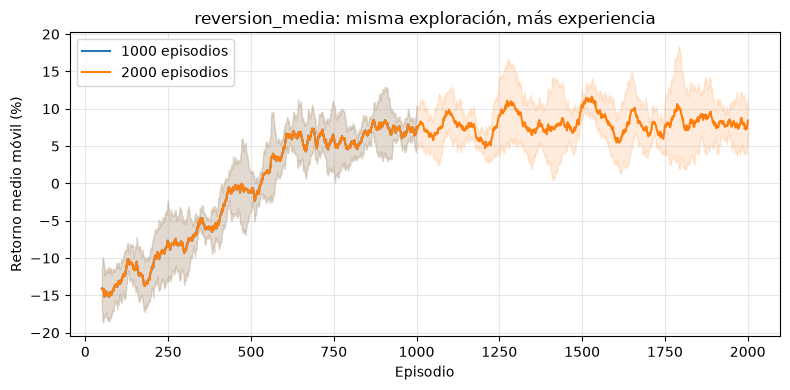

In [14]:
if duration_results:
    fig, axes = plt.subplots(1, len(duration_results), figsize=(8 * len(duration_results), 4), squeeze=False)
    for ax, (name, results) in zip(axes.flat, duration_results.items()):
        for label, color in (("base", "tab:blue"), ("extended", "tab:orange")):
            candidate = results[label]
            curves = np.stack([np.convolve([h["return"] for h in run["history"]], np.ones(50)/50, mode="valid") for run in candidate["runs"]])
            x = np.arange(50, candidate["config"]["n_episodes"]+1)
            mean, std = 100*curves.mean(axis=0), 100*curves.std(axis=0, ddof=1)
            ax.plot(x, mean, color=color, label=f"{candidate['config']['n_episodes']} episodios")
            ax.fill_between(x, mean-std, mean+std, color=color, alpha=0.15)
        ax.set(title=f"{name}: misma exploración, más experiencia", xlabel="Episodio", ylabel="Retorno medio móvil (%)")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()


### Decisión final de duración — antes de test

**Mantenemos 1.000 episodios para los cuatro mercados.** En reversión a la media, ampliar a 2.000 reduce el retorno medio de validación de **11,26 % a 5,62 %**. Solo **dos de cinco semillas** mejoran. El P05 mejora de **−14,33 % a −1,14 %** y la desviación entre semillas baja ligeramente, de **9,72 % a 9,12 %**, pero la mediana cae a cero y las operaciones medias pasan de **59,60 a 3,02**. El tiempo medio aumenta de **48,2 a 98,4 segundos**.

La ampliación ofrece un resultado más conservador, pero no mejora el criterio principal de retorno medio fijado antes de la búsqueda. No cambiamos ese criterio después de ver los resultados. Conservamos los modelos extendidos y mostramos sus métricas, sin seleccionarlos para test. La decisión y las configuraciones quedan congeladas en `duration_decision.json` antes de la evaluación final.


## 8. Curvas y convergencia aproximada

Dibujamos cada semilla por separado para no ocultar inestabilidad. Reutilizamos el criterio de Higinio: bloques de 50 episodios, cambios relativos inferiores al 5 % y al menos tres cambios estables, con suelo de escala 0,01. Es una descripción retrospectiva de estabilidad, no prueba de optimalidad. En la prueba corta no hay episodios suficientes para estimarlo.


In [15]:
def estimate_convergence_episode(
    episode_returns,
    block_size=50,
    change_threshold=0.05,
    stable_blocks=3,
    relative=True,
    scale_floor=0.01,
):
    """Estima el primer episodio desde el que el retorno se estabiliza."""
    episode_returns = np.asarray(episode_returns, dtype=np.float64)
    if episode_returns.ndim != 1:
        raise ValueError("episode_returns debe ser un vector")
    if not np.all(np.isfinite(episode_returns)):
        raise ValueError("episode_returns debe contener valores finitos")
    if (
        isinstance(block_size, (bool, np.bool_))
        or not isinstance(block_size, (int, np.integer))
        or block_size <= 0
    ):
        raise ValueError("block_size debe ser un entero positivo")
    if change_threshold < 0:
        raise ValueError("change_threshold no puede ser negativo")
    if (
        isinstance(stable_blocks, (bool, np.bool_))
        or not isinstance(stable_blocks, (int, np.integer))
        or stable_blocks <= 0
    ):
        raise ValueError("stable_blocks debe ser un entero positivo")
    if not isinstance(relative, (bool, np.bool_)):
        raise ValueError("relative debe ser booleano")
    if scale_floor <= 0:
        raise ValueError("scale_floor debe ser positivo")

    n_complete_blocks = episode_returns.size // block_size
    if n_complete_blocks < stable_blocks + 1:
        return None

    usable_episodes = n_complete_blocks * block_size
    block_mean_returns = episode_returns[:usable_episodes].reshape(
        n_complete_blocks, block_size
    ).mean(axis=1)
    changes = np.abs(np.diff(block_mean_returns))
    if relative:
        scale = np.maximum(
            np.abs(block_mean_returns[:-1]), scale_floor
        )
        changes = changes / scale

    last_candidate = changes.size - stable_blocks
    for change_index in range(last_candidate + 1):
        if np.all(changes[change_index:] <= change_threshold):
            return int((change_index + 2) * block_size)

    return None


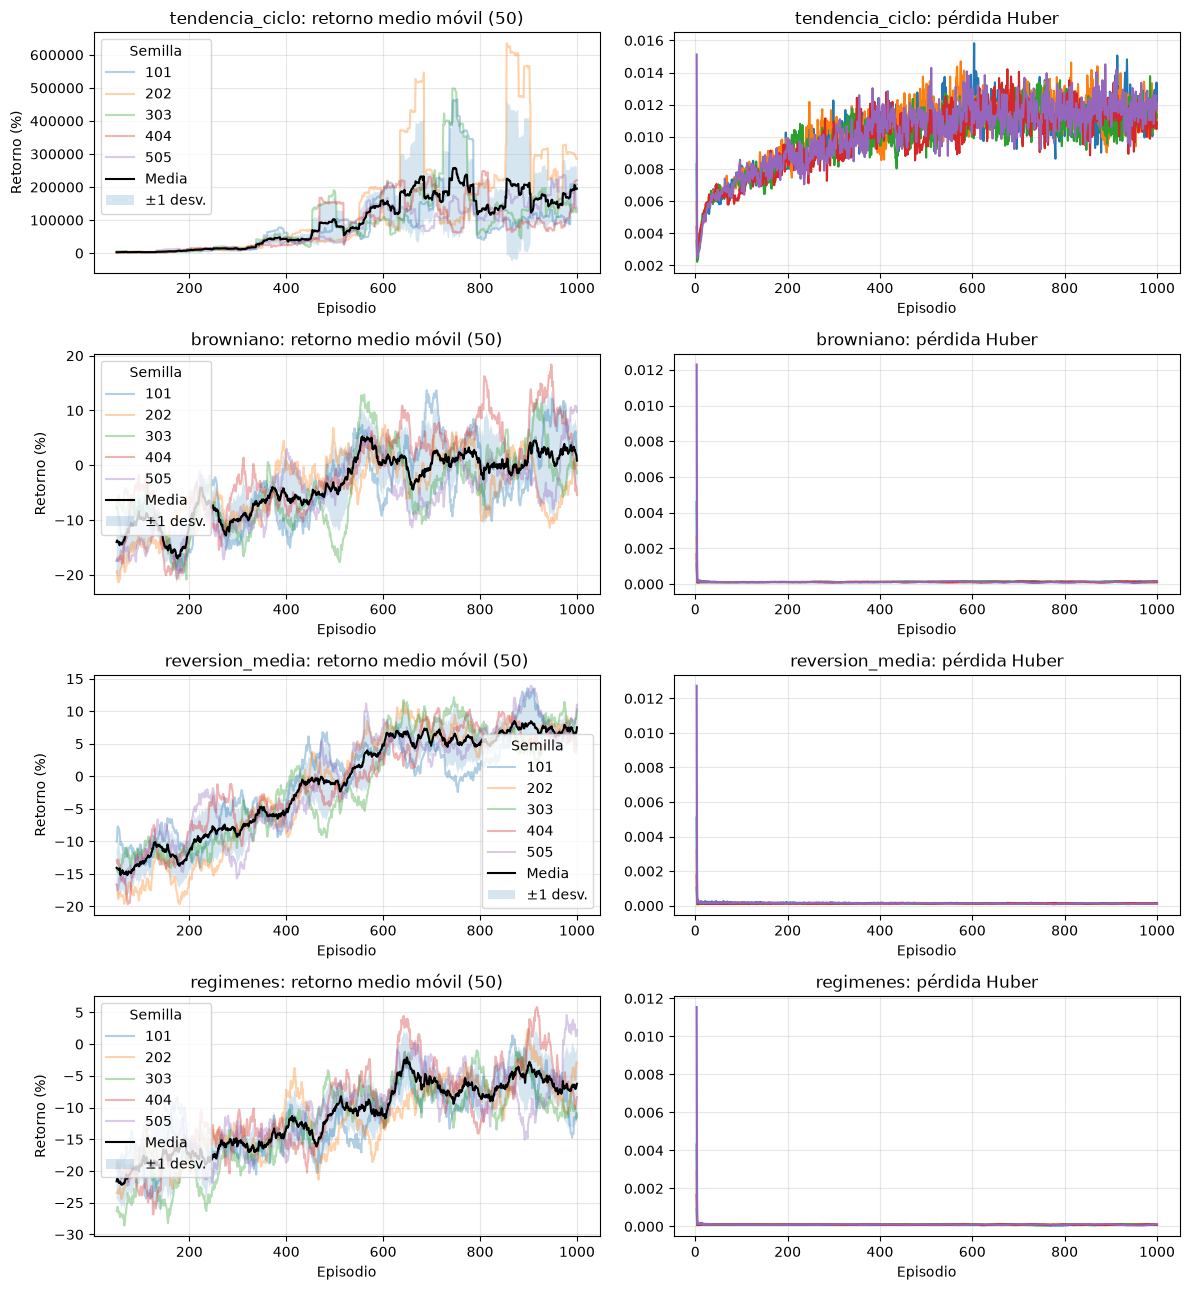

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for row, (name, candidate) in enumerate(selected.items()):
    curves = []
    for run in candidate["runs"]:
        history = run["history"]
        window = 50 if len(history) >= 50 else 1
        returns = np.array([h["return"] for h in history])
        smoothed = np.convolve(returns, np.ones(window) / window, mode="valid")
        curves.append(smoothed)
        axes[row, 0].plot(np.arange(window, len(history) + 1), 100 * smoothed, alpha=0.35,
                          label=str(run["training_seed"]), marker="o" if MODE == "smoke" else None)
        axes[row, 1].plot([h["episode"] for h in history],
                          [np.nan if h["loss"] is None else h["loss"] for h in history])
    x = np.arange(window, len(history) + 1)
    mean = 100 * np.mean(curves, axis=0)
    std = 100 * np.std(curves, axis=0, ddof=1)
    axes[row, 0].plot(x, mean, color="black", label="Media")
    axes[row, 0].fill_between(x, mean-std, mean+std, alpha=0.18, label="±1 desv.")
    axes[row, 0].set_ylabel("Retorno (%)")
    axes[row, 0].set_title(f"{name}: retorno medio móvil ({window})")
    axes[row, 1].set_title(f"{name}: pérdida Huber")
    for ax in axes[row]:
        ax.set_xlabel("Episodio")
        ax.grid(alpha=0.3)
    axes[row, 0].legend(title="Semilla")
plt.tight_layout()
plt.show()


### Trayectorias y exploración

Mostramos la primera serie de validación y el modelo de la primera semilla del protocolo, fijados antes de ver resultados. El ejemplo no sustituye las métricas agregadas. Todas las estrategias comparten precios, comisiones y eje temporal; el capital inicial corresponde al instante 5 y la primera transición termina en 6. Los puntos muestran la posición después de actuar; los triángulos indican operaciones reales.


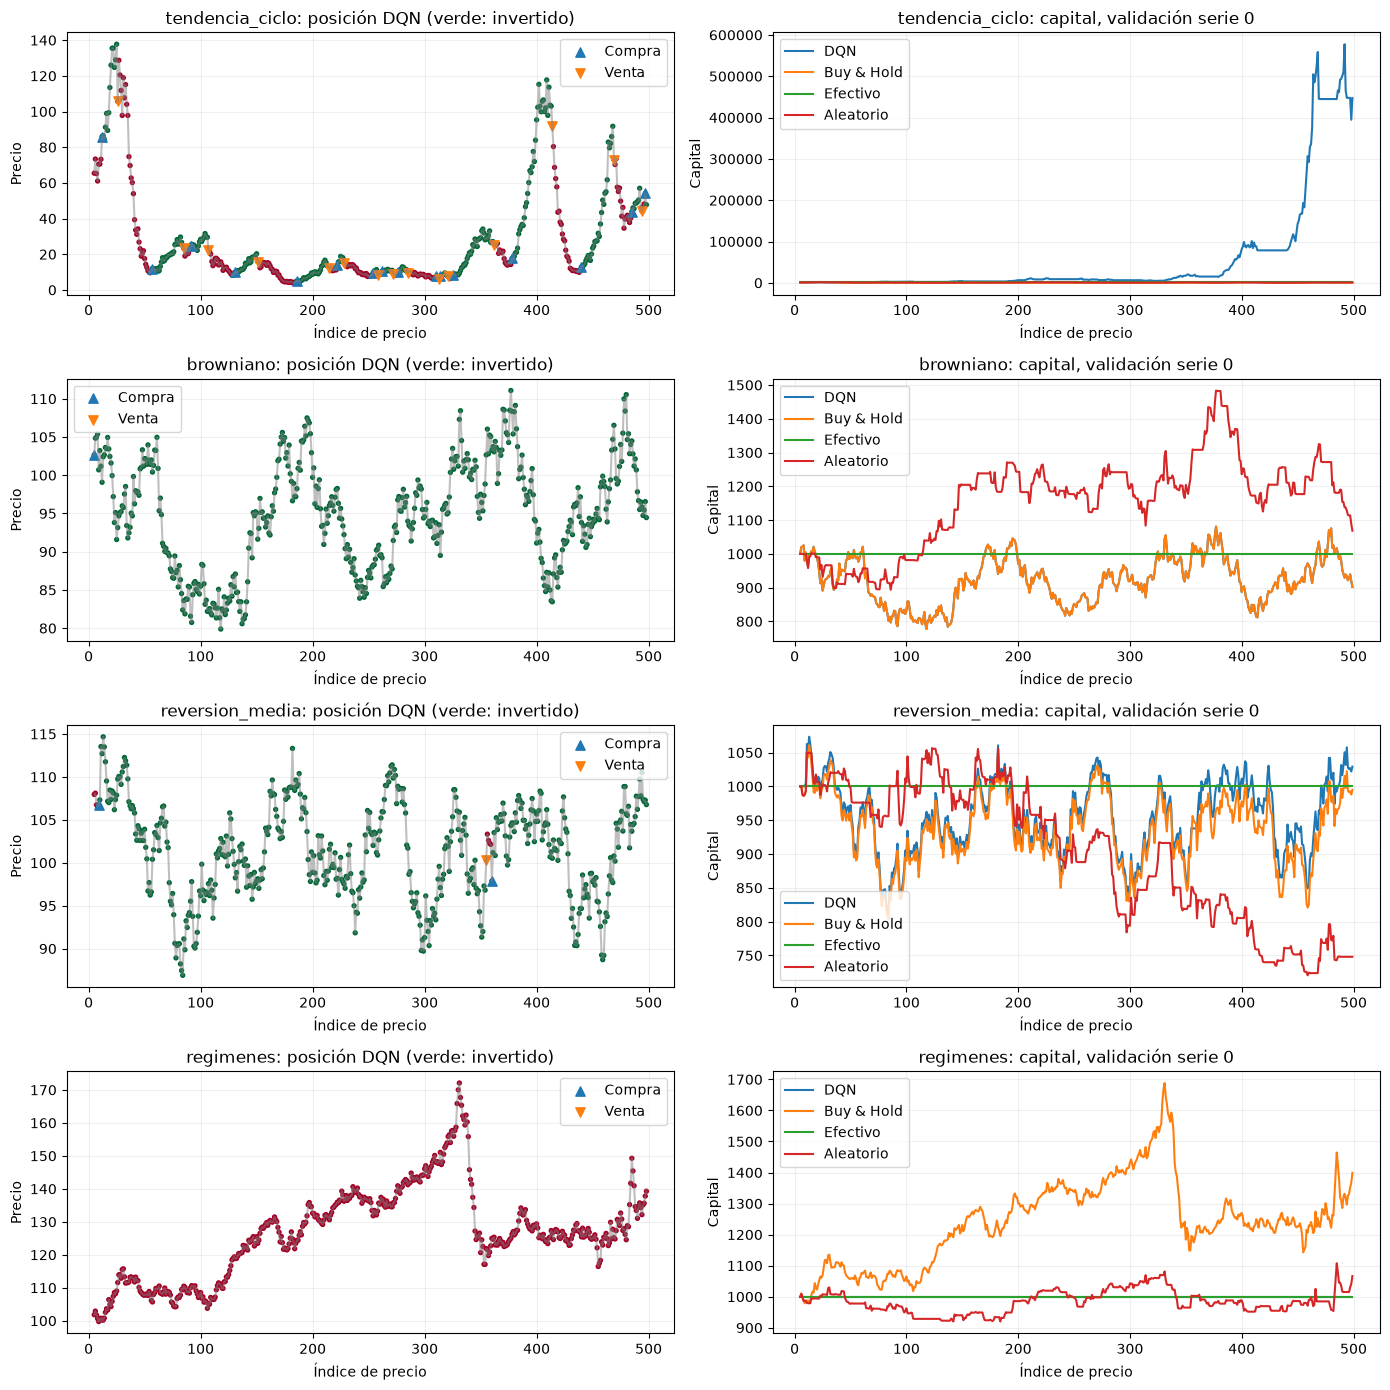

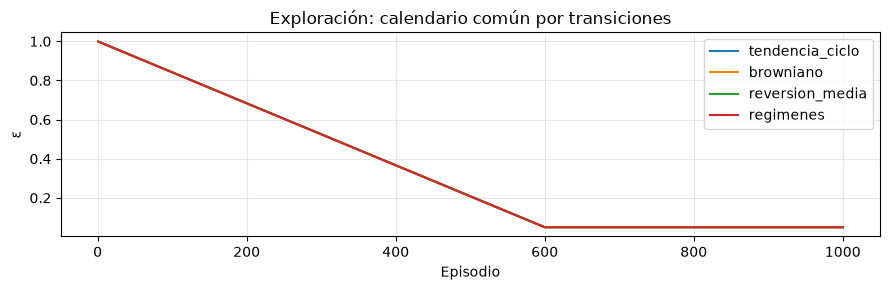

In [17]:
def trace_policy(prices, choose):
    env = SimpleTradingEnv(prices)
    state, _ = env.reset()
    balances, positions, trades = [env.balance], [], []
    done = False
    while not done:
        previous = env.position
        action = choose(state, env)
        state, _, terminated, truncated, _ = env.step(action)
        positions.append(env.position)
        trades.append(env.position - previous)
        balances.append(env.balance)
        done = terminated or truncated
    return np.array(balances), np.array(positions), np.array(trades)

fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for row, (name, candidate) in enumerate(selected.items()):
    prices = VALIDATION_DATASETS[name][0]
    run = candidate["runs"][0]
    model = QNetwork(run["config"]["hidden_dim"])
    model.load_state_dict(run["model_state_dict"])
    model.eval()
    def choose_dqn(state, env):
        with torch.no_grad():
            return int(model(torch.from_numpy(state)).argmax())
    gid, _ = PRICE_GENERATORS[name]
    rng = VALIDATION_PROTOCOL.action_rng(gid, 0)
    policies = {"DQN": choose_dqn, "Buy & Hold": lambda s,e: 2 if e.current_step == 5 else 1,
                "Efectivo": lambda s,e: 1, "Aleatorio": lambda s,e: int(rng.integers(3))}
    for label, policy in policies.items():
        balances, positions, trades = trace_policy(prices, policy)
        axes[row,1].plot(np.arange(5,len(prices)), balances, label=label)
        if label == "DQN":
            time = np.arange(5,len(prices)-1)
            axes[row,0].plot(time,prices[5:-1],color="gray",alpha=0.5)
            axes[row,0].scatter(time,prices[5:-1],c=positions,cmap="RdYlGn",vmin=0,vmax=1,s=8)
            for change,marker,label_trade in [(1,"^","Compra"),(-1,"v","Venta")]:
                mask=trades==change
                axes[row,0].scatter(time[mask],prices[5:-1][mask],marker=marker,s=45,label=label_trade)
    axes[row,0].set(title=f"{name}: posición DQN (verde: invertido)",ylabel="Precio")
    axes[row,1].set(title=f"{name}: capital, validación serie 0",ylabel="Capital")
    for ax in axes[row]:
        ax.set_xlabel("Índice de precio")
        ax.grid(alpha=0.2)
        ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9,3))
for name,candidate in selected.items():
    history=candidate["runs"][0]["history"]
    ax.plot([h["episode"] for h in history],[h["epsilon"] for h in history],label=name)
ax.set(xlabel="Episodio",ylabel="ε",title="Exploración: calendario común por transiciones")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Test final y tabla comparable

Solo `full` abre la evaluación final: 200 series por mercado para cada una de las cinco semillas del modelo seleccionado. El resultado se guarda y se reutiliza mientras no cambie el experimento. Después de observar test no debemos reajustar el modelo usando esa información.

La tabla de `smoke` contiene únicamente validación y se identifica expresamente como prueba técnica. Los tiempos dependen del hardware; la convergencia se informa solo cuando el criterio común la detecta.

Antes de test se exige `duration_decision.json`, que documenta la decisión sobre duración basada en validación y las configuraciones congeladas. Esto evita ejecutar test automáticamente antes de esa revisión.

La decisión revisada también se incluye en el código como `FROZEN_DURATION_DECISION`. En un checkout nuevo se recupera desde ahí si coinciden el código experimental y las configuraciones seleccionadas; una reproducción distinta exige revisar validación antes de test.


In [18]:
configuration_table = ["| Mercado | Episodios | Precios | LR | γ | Batch | Replay | Actualizar cada | Copiar objetivo cada | ε: pasos de decaimiento |", "|---|---|---|---|---|---|---|---|---|---|"]
for name, candidate in selected.items():
    config = candidate["config"]
    values = [name] + [str(config[key]) for key in ("n_episodes", "n_steps", "learning_rate", "gamma", "batch_size", "buffer_size", "train_every", "target_every", "epsilon_decay_steps")]
    configuration_table.append("| " + " | ".join(values) + " |")
display(Markdown("### Configuraciones seleccionadas\n\n" + "\n".join(configuration_table)))
(OUTPUT_DIR / "selected_configurations.md").write_text("\n".join(configuration_table))


### Configuraciones seleccionadas

| Mercado | Episodios | Precios | LR | γ | Batch | Replay | Actualizar cada | Copiar objetivo cada | ε: pasos de decaimiento |
|---|---|---|---|---|---|---|---|---|---|
| tendencia_ciclo | 1000 | 500 | 0.0003 | 0.99 | 64 | 20000 | 4 | 250 | 296400 |
| browniano | 1000 | 500 | 0.0003 | 0.95 | 64 | 20000 | 4 | 250 | 296400 |
| reversion_media | 1000 | 500 | 0.0003 | 0.99 | 64 | 20000 | 4 | 250 | 296400 |
| regimenes | 1000 | 500 | 0.0003 | 0.95 | 64 | 20000 | 4 | 250 | 296400 |

480

In [19]:
FROZEN_DURATION_DECISION = {'created_at_utc': '2026-11-03T00:05:43.965702+00:00',
 'code_hash': 'c1de41f985374bf0acfe3d8697566471718ce4caf747532778f777c0b2fdf70b',
 'selected_configs': {'tendencia_ciclo': {'n_episodes': 1000,
                                          'n_steps': 500,
                                          'hidden_dim': 32,
                                          'learning_rate': 0.0003,
                                          'gamma': 0.99,
                                          'buffer_size': 20000,
                                          'batch_size': 64,
                                          'learning_starts': 1000,
                                          'train_every': 4,
                                          'target_every': 250,
                                          'epsilon_start': 1.0,
                                          'epsilon_end': 0.05,
                                          'epsilon_decay_steps': 296400,
                                          'max_gradient_norm': 10.0},
                      'browniano': {'n_episodes': 1000,
                                    'n_steps': 500,
                                    'hidden_dim': 32,
                                    'learning_rate': 0.0003,
                                    'gamma': 0.95,
                                    'buffer_size': 20000,
                                    'batch_size': 64,
                                    'learning_starts': 1000,
                                    'train_every': 4,
                                    'target_every': 250,
                                    'epsilon_start': 1.0,
                                    'epsilon_end': 0.05,
                                    'epsilon_decay_steps': 296400,
                                    'max_gradient_norm': 10.0},
                      'reversion_media': {'n_episodes': 1000,
                                          'n_steps': 500,
                                          'hidden_dim': 32,
                                          'learning_rate': 0.0003,
                                          'gamma': 0.99,
                                          'buffer_size': 20000,
                                          'batch_size': 64,
                                          'learning_starts': 1000,
                                          'train_every': 4,
                                          'target_every': 250,
                                          'epsilon_start': 1.0,
                                          'epsilon_end': 0.05,
                                          'epsilon_decay_steps': 296400,
                                          'max_gradient_norm': 10.0},
                      'regimenes': {'n_episodes': 1000,
                                    'n_steps': 500,
                                    'hidden_dim': 32,
                                    'learning_rate': 0.0003,
                                    'gamma': 0.95,
                                    'buffer_size': 20000,
                                    'batch_size': 64,
                                    'learning_starts': 1000,
                                    'train_every': 4,
                                    'target_every': 250,
                                    'epsilon_start': 1.0,
                                    'epsilon_end': 0.05,
                                    'epsilon_decay_steps': 296400,
                                    'max_gradient_norm': 10.0}},
 'extended_markets': ['reversion_media'],
 'use_extended': [],
 'reason': 'Se mantienen 1000 episodios: en reversión 2000 reduce retorno medio de validación de '
           '11.26% a 5.62%; mejora P05 pero solo mejoran 2/5 semillas y duplica tiempo. Se '
           'conserva el criterio primario predefinido de retorno medio y el presupuesto común. En '
           'los otros mercados no se amplía por las razones documentadas en el notebook; no se '
           'afirma que más experiencia sea inútil.'}

# El test requiere una decisión explícita basada únicamente en validación.
if MODE == "full":
    decision_path = OUTPUT_DIR / "duration_decision.json"
    if decision_path.exists():
        duration_decision = json.loads(decision_path.read_text())
    else:
        duration_decision = FROZEN_DURATION_DECISION
        if (duration_decision["code_hash"] != CODE_HASH
                or duration_decision["selected_configs"] != {name: c["config"] for name,c in selected.items()}):
            raise RuntimeError("La reproducción difiere del experimento revisado; revisar validación antes de test")
        decision_path.write_text(json.dumps(duration_decision, ensure_ascii=False, indent=2))
    assert duration_decision["code_hash"] == CODE_HASH
    assert duration_decision["selected_configs"] == {name: c["config"] for name,c in selected.items()}

final_identity = {"code": CODE_HASH, "mode": MODE,
                  "torch": str(torch.__version__), "numpy": np.__version__,
                  "configs": {name: c["config"] for name, c in selected.items()},
                  "seeds": list(seeds), "test": EXPECTED_TEST_FINGERPRINTS}
final_path = OUTPUT_DIR / "final_evaluation.pt"
if MODE == "full" and final_path.exists():
    final_payload = torch.load(final_path, map_location="cpu", weights_only=False)
    if final_payload["identity"] != final_identity:
        raise ValueError("El test guardado pertenece a otro experimento; conserva el artefacto antes de cambiarlo")
    evaluation_results = final_payload["results"]
else:
    evaluation_results = {}
    for name, candidate in selected.items():
        if MODE == "full":
            evaluations = [evaluate_dqn(run, TEST_DATASETS[name]) for run in candidate["runs"]]
            baselines = evaluate_test_baselines(name)
        else:
            evaluations = candidate["validation"]
            generator_id, _ = PRICE_GENERATORS[name]
            factories = {
                "cash": lambda i: lambda state, env: 1,
                "buy_and_hold": lambda i: lambda state, env: 2 if env.current_step == 5 else 1,
                "random": lambda i: (lambda rng: lambda state, env: int(rng.integers(3)))(
                    VALIDATION_PROTOCOL.action_rng(generator_id, i)),
            }
            baselines = {key: evaluate_rule_based_policy(validation[name], factory)
                         for key, factory in factories.items()}
        evaluation_results[name] = {"dqn": evaluations,
                                     "summary": summarize_evaluations(evaluations),
                                     "baselines": baselines}
    final_payload = {"identity": final_identity, "results": evaluation_results,
                     "hardware": platform.platform(), "processor": platform.processor(),
                     "device": "cpu", "torch_threads": torch.get_num_threads()}
    atomic_save(final_payload, final_path)

rows = []
for name, result in evaluation_results.items():
    runs = selected[name]["runs"]
    episodes = [estimate_convergence_episode([h["return"] for h in run["history"]])
                for run in runs]
    seconds = [run["history"][episode - 1]["elapsed_seconds"]
               for run, episode in zip(runs, episodes) if episode is not None]
    rows.append({"market": name, "model": "DQN", **result["summary"],
                 "training_seconds": float(np.mean([r["training_seconds"] for r in runs])),
                 "convergence_episode": float(np.mean([e for e in episodes if e is not None])) if seconds else None,
                 "convergence_seconds": float(np.mean(seconds)) if seconds else None,
                 "convergence_rate": len(seconds) / len(runs)})
    for label, baseline in result["baselines"].items():
        rows.append({"market": name, "model": label, **baseline,
                     "std_between_seeds": None, "training_seconds": None,
                     "convergence_episode": None, "convergence_seconds": None,
                     "convergence_rate": None})

def format_metric(value, percent=False):
    return "—" if value is None else (f"{value:.2%}" if percent else f"{value:.2f}")

heading = "TEST FINAL" if MODE == "full" else "PRUEBA TÉCNICA — VALIDACIÓN, NO COMPARACIÓN FINAL"
table = [f"### {heading}", "",
         "| Mercado | Modelo | Retorno | Desv. series | Desv. semillas | P05 | Operaciones | Train (s) | Eval (s) | Conv. episodio | Conv. (s) | Tasa conv. |",
         "|" + "---|" * 12]
for row in rows:
    metrics = [format_metric(row[key], percent) for key, percent in (
        ("mean_return", True), ("std_return", True), ("std_between_seeds", True),
        ("return_percentile_05", True), ("mean_trade_count", False),
        ("training_seconds", False), ("evaluation_seconds", False),
        ("convergence_episode", False), ("convergence_seconds", False), ("convergence_rate", True))]
    table.append("| " + " | ".join([row["market"], row["model"], *metrics]) + " |")
display(Markdown("\n".join(table)))
(OUTPUT_DIR / "comparison.md").write_text("\n".join(table))


### TEST FINAL

| Mercado | Modelo | Retorno | Desv. series | Desv. semillas | P05 | Operaciones | Train (s) | Eval (s) | Conv. episodio | Conv. (s) | Tasa conv. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| tendencia_ciclo | DQN | 346090.85% | 4009514.57% | 294886.99% | 1661.27% | 59.60 | 48.10 | 2.40 | — | — | 0.00% |
| tendencia_ciclo | cash | 0.00% | 0.00% | — | 0.00% | 0.00 | — | 0.69 | — | — | — |
| tendencia_ciclo | buy_and_hold | 42092.90% | 318054.92% | — | -16.68% | 1.00 | — | 0.71 | — | — | — |
| tendencia_ciclo | random | 1479.75% | 3585.04% | — | -74.82% | 165.69 | — | 0.79 | — | — | — |
| browniano | DQN | 1.82% | 22.78% | 4.06% | -24.63% | 0.20 | 48.22 | 2.37 | — | — | 0.00% |
| browniano | cash | 0.00% | 0.00% | — | 0.00% | 0.00 | — | 0.67 | — | — | — |
| browniano | buy_and_hold | 9.08% | 50.28% | — | -51.16% | 1.00 | — | 0.69 | — | — | — |
| browniano | random | -10.62% | 32.62% | — | -51.32% | 164.91 | — | 0.79 | — | — | — |
| reversion_media | DQN | 8.31% | 21.10% | 11.71% | -21.02% | 59.45 | 48.25 | 2.36 | — | — | 0.00% |
| reversion_media | cash | 0.00% | 0.00% | — | 0.00% | 0.00 | — | 0.67 | — | — | — |
| reversion_media | buy_and_hold | -0.30% | 7.60% | — | -11.68% | 1.00 | — | 0.68 | — | — | — |
| reversion_media | random | -13.04% | 20.59% | — | -41.58% | 165.78 | — | 0.81 | — | — | — |
| regimenes | DQN | 0.00% | 0.00% | 0.00% | 0.00% | 0.00 | 48.37 | 2.36 | — | — | 0.00% |
| regimenes | cash | 0.00% | 0.00% | — | 0.00% | 0.00 | — | 0.67 | — | — | — |
| regimenes | buy_and_hold | -9.21% | 38.72% | — | -61.76% | 1.00 | — | 0.68 | — | — | — |
| regimenes | random | -18.81% | 25.33% | — | -56.76% | 165.22 | — | 0.82 | — | — | — |

1689

## 10. Interpretación y siguiente comparación

- En `smoke` solo verificamos que el código entrena, evalúa y guarda artefactos. Cuatro episodios no permiten juzgar DQN.
- En `full`, comparar DQN y A3C por mercado, sobre las mismas huellas, con cinco semillas y el mismo presupuesto de experiencia por modelo. Declarar la distinta búsqueda de hiperparámetros y el hardware.
- Revisar percentil 5, operaciones y dispersión además del retorno medio. Una política sin operaciones puede ser simplemente permanecer en efectivo.
- No confundir estabilidad del retorno con optimalidad; el decaimiento de ε también afecta las curvas de entrenamiento.
- Las cifras del generador de tendencia no son extrapolables a mercados reales.

Los artefactos contienen pesos, configuraciones, historial, evaluaciones por serie y huellas. Solo se deben cargar archivos `.pt` generados localmente por este experimento. No añadimos cifras de A3C a mano: deben proceder de su artefacto final verificado.


### Conclusiones calculadas a partir de test

Esta sección solo interpreta la evaluación final de los modelos congelados. Compara retorno y riesgo con los baselines; no sirve para volver a ajustar hiperparámetros. La dispersión entre semillas resume cinco medias, mientras que la dispersión entre series agrupa resultados correlacionados porque todos los modelos comparten el banco de precios.


In [20]:
if MODE == "full":
    conclusions = ["## Conclusiones de test", ""]
    for name, result in evaluation_results.items():
        summary = result["summary"]
        baselines = result["baselines"]
        baseline_text = "; ".join(f"{label}: {metrics['mean_return']:.2%}" for label,metrics in baselines.items())
        better = [label for label,metrics in baselines.items() if summary["mean_return"] > metrics["mean_return"]]
        comparison = "Supera en retorno medio a " + ", ".join(better) + "." if better else "No supera en retorno medio a ninguno de los baselines."
        all_cash = all(np.all(e["trade_counts"] == 0) for e in result["dqn"])
        policy_note = "Todos los modelos permanecen en efectivo; no hay evidencia de trading activo." if all_cash else "El número de operaciones confirma actividad en al menos parte de las evaluaciones; no garantiza una política estable."
        text = (f"**{name}**: retorno medio {summary['mean_return']:.2%}, mediana {summary['median_return']:.2%}, "
                f"P05 {summary['return_percentile_05']:.2%}, dispersión entre semillas {summary['std_between_seeds']:.2%}, "
                f"y {summary['mean_trade_count']:.2f} operaciones por serie. Baselines: {baseline_text}. {comparison} {policy_note}")
        if name == "tendencia_ciclo":
            text += " La escala de este mercado puede ser extrema por su generador; estos retornos no son extrapolables a mercados reales."
        conclusions.append("- " + text)
    conclusions.extend(["", "Las comparaciones son descriptivas sobre las mismas 200 series y cinco semillas, no pruebas de significación estadística. No se han reajustado modelos después de observar test."])
    display(Markdown("\n".join(conclusions)))
    (OUTPUT_DIR / "test_conclusions.md").write_text("\n".join(conclusions))
else:
    print("Modo smoke: no hay conclusiones sobre rendimiento final.")


## Conclusiones de test

- **tendencia_ciclo**: retorno medio 346090.85%, mediana 35242.23%, P05 1661.27%, dispersión entre semillas 294886.99%, y 59.60 operaciones por serie. Baselines: cash: 0.00%; buy_and_hold: 42092.90%; random: 1479.75%. Supera en retorno medio a cash, buy_and_hold, random. El número de operaciones confirma actividad en al menos parte de las evaluaciones; no garantiza una política estable. La escala de este mercado puede ser extrema por su generador; estos retornos no son extrapolables a mercados reales.
- **browniano**: retorno medio 1.82%, mediana 0.00%, P05 -24.63%, dispersión entre semillas 4.06%, y 0.20 operaciones por serie. Baselines: cash: 0.00%; buy_and_hold: 9.08%; random: -10.62%. Supera en retorno medio a cash, random. El número de operaciones confirma actividad en al menos parte de las evaluaciones; no garantiza una política estable.
- **reversion_media**: retorno medio 8.31%, mediana 4.86%, P05 -21.02%, dispersión entre semillas 11.71%, y 59.45 operaciones por serie. Baselines: cash: 0.00%; buy_and_hold: -0.30%; random: -13.04%. Supera en retorno medio a cash, buy_and_hold, random. El número de operaciones confirma actividad en al menos parte de las evaluaciones; no garantiza una política estable.
- **regimenes**: retorno medio 0.00%, mediana 0.00%, P05 0.00%, dispersión entre semillas 0.00%, y 0.00 operaciones por serie. Baselines: cash: 0.00%; buy_and_hold: -9.21%; random: -18.81%. Supera en retorno medio a buy_and_hold, random. Todos los modelos permanecen en efectivo; no hay evidencia de trading activo.

Las comparaciones son descriptivas sobre las mismas 200 series y cinco semillas, no pruebas de significación estadística. No se han reajustado modelos después de observar test.

### Lectura crítica de los resultados finales

- **Tendencia y ciclo:** el retorno medio de DQN (346.090,85 %) supera buy & hold (42.092,90 %), pero la mediana es mucho menor y la dispersión entre semillas alcanza 294.886,99 %. El comportamiento explosivo del generador domina la escala. No lo interpretamos como evidencia de rentabilidad financiera real.
- **Browniano:** el 1,82 % agregado procede de una semilla que compra y mantiene y cuatro que permanecen en efectivo. Por eso el promedio equivale aproximadamente a una quinta parte del retorno de buy & hold (9,08 %). No demuestra que DQN haya descubierto una señal predictiva.
- **Reversión a la media:** DQN supera los tres baselines en media (8,31 %), pero su P05 es −21,02 % y la dispersión entre semillas es 11,71 %, mayor que la media. Hay aprendizaje útil en este entorno, acompañado de riesgo y sensibilidad a la inicialización. El estudio de 2.000 episodios se resolvió exclusivamente en validación; no se reconsidera tras observar test.
- **Regímenes:** el 0 % coincide con efectivo y cero operaciones en las cinco semillas. Evita las pérdidas medias de los otros baselines, pero no demuestra que explote los cambios de régimen.

Los tiempos son mediciones locales en CPU, no un benchmark controlado frente a A3C. Se han entrenado **80 modelos base y 5 extendidos**. La comparación principal conserva 1.000 episodios y las mismas cinco semillas; el presupuesto de búsqueda de hiperparámetros difiere del de A3C.
